In [1]:
!pip install google-play-scraper -q

In [2]:
from google_play_scraper import app, search
import pandas as pd
import time

In [3]:
# Narrower, more specific search terms pull a fresh top-30 each time,
# giving you far more unique apps than broad category names
search_terms = [
    'action games', 'puzzle games', 'racing games', 'card games', 'arcade games',
    'language learning', 'exam prep', 'kids education', 'online courses',
    'budgeting app', 'stock trading', 'banking app', 'crypto wallet',
    'fitness tracker', 'meditation app', 'diet planner', 'workout app',
    'messaging app', 'dating app', 'photo sharing', 'video call',
    'file manager', 'vpn app', 'note taking', 'pdf reader',
    'music streaming', 'podcast app', 'audio editor', 'radio app',
    'online shopping', 'grocery delivery', 'fashion shopping', 'coupon app'
]

all_apps = []
seen_ids = set()  # avoid duplicate apps across search terms

for term in search_terms:
    try:
        results = search(term, lang='en', country='in', n_hits=30)  # 30 is Google's own cap per query
    except Exception as e:
        print(f"Search failed for '{term}': {e}")
        continue

    new_count = 0
    for r in results:
        app_id = r['appId']
        if app_id in seen_ids:
            continue
        seen_ids.add(app_id)

        try:
            details = app(app_id, lang='en', country='in')
            all_apps.append({
                'app_id': app_id,
                'name': details['title'],
                'category': details['genre'],
                'installs': details['installs'],         # text range e.g. "10,000,000+"
                'min_installs': details['minInstalls'],   # numeric lower bound
                'rating': details['score'],
                'reviews': details['ratings'],
                'size': details.get('size'),
                'price': details['price'],
                'free': details['free'],
                'content_rating': details['contentRating'],
                'last_updated': details.get('updated')
            })
            new_count += 1
        except Exception as e:
            print(f"Skipped {app_id}: {e}")

        time.sleep(0.3)  # be polite, avoid rate limiting

    print(f"'{term}': +{new_count} new apps (total so far: {len(all_apps)})")

print(f"\nDone. Total unique apps collected: {len(all_apps)}")

'action games': +30 new apps (total so far: 30)
'puzzle games': +29 new apps (total so far: 59)
'racing games': +27 new apps (total so far: 86)
'card games': +29 new apps (total so far: 115)
'arcade games': +16 new apps (total so far: 131)
'language learning': +30 new apps (total so far: 161)
'exam prep': +30 new apps (total so far: 191)
'kids education': +27 new apps (total so far: 218)
'online courses': +11 new apps (total so far: 229)
'budgeting app': +30 new apps (total so far: 259)
'stock trading': +30 new apps (total so far: 289)
'banking app': +30 new apps (total so far: 319)
'crypto wallet': +22 new apps (total so far: 341)
'fitness tracker': +29 new apps (total so far: 370)
'meditation app': +27 new apps (total so far: 397)
'diet planner': +24 new apps (total so far: 421)
'workout app': +22 new apps (total so far: 443)
'messaging app': +30 new apps (total so far: 473)
'dating app': +22 new apps (total so far: 495)
'photo sharing': +30 new apps (total so far: 525)
'video call':

In [4]:
df = pd.DataFrame(all_apps)
print(df.shape)
df.head()

(820, 12)


,app_id,name,category,installs,min_installs,rating,reviews,size,price,free,content_rating,last_updated
0,com.dts.freefiremax,Free Fire MAX x NARUTO,Action,"500,000,000+",500000000,4.335896,32249294.0,None,0.0,True,Rated for 16+,1.789012e+09
1,com.generagames.resistance,Cover Fire: Offline Shooting,Action,"100,000,000+",100000000,4.193770,2571828.0,None,0.0,True,Rated for 16+,1.788447e+09
2,com.roblox.client,Roblox,Adventure,"1,000,000,000+",1000000000,4.686732,53306210.0,None,0.0,True,Rated for 12+,1.792612e+09
3,com.herogames.gplay.crisisactionsa,Crisis Action: 7th Anniversary,Action,"10,000,000+",10000000,3.536364,837813.0,None,0.0,True,Rated for 16+,1.788329e+09
4,com.levelinfinite.gst,Gangstar Mirage City: Online,Role Playing,"10,000,000+",10000000,4.510063,139455.0,None,0.0,True,Rated for 18+,1.786086e+09


In [5]:
df.to_csv('playstore_apps.csv', index=False)
print("Saved playstore_apps.csv")

# Download it to your computer
from google.colab import files
files.download('playstore_apps.csv')

Saved playstore_apps.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv('playstore_apps.csv')
print(df.shape)
df.head()

(820, 12)


,app_id,name,category,installs,min_installs,rating,reviews,size,price,free,content_rating,last_updated
0,com.dts.freefiremax,Free Fire MAX x NARUTO,Action,"500,000,000+",500000000,4.335896,32249294.0,NaN,0.0,True,Rated for 16+,1.789012e+09
1,com.generagames.resistance,Cover Fire: Offline Shooting,Action,"100,000,000+",100000000,4.193770,2571828.0,NaN,0.0,True,Rated for 16+,1.788447e+09
2,com.roblox.client,Roblox,Adventure,"1,000,000,000+",1000000000,4.686732,53306210.0,NaN,0.0,True,Rated for 12+,1.792612e+09
3,com.herogames.gplay.crisisactionsa,Crisis Action: 7th Anniversary,Action,"10,000,000+",10000000,3.536364,837813.0,NaN,0.0,True,Rated for 16+,1.788329e+09
4,com.levelinfinite.gst,Gangstar Mirage City: Online,Role Playing,"10,000,000+",10000000,4.510063,139455.0,NaN,0.0,True,Rated for 18+,1.786086e+09


In [7]:
print(df.info())
print("\nMissing values per column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 820 entries, 0 to 819
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_id          820 non-null    object 
 1   name            820 non-null    object 
 2   category        820 non-null    object 
 3   installs        820 non-null    object 
 4   min_installs    820 non-null    int64  
 5   rating          786 non-null    float64
 6   reviews         786 non-null    float64
 7   size            0 non-null      float64
 8   price           820 non-null    float64
 9   free            820 non-null    bool   
 10  content_rating  820 non-null    object 
 11  last_updated    760 non-null    float64
dtypes: bool(1), float64(5), int64(1), object(5)
memory usage: 71.4+ KB
None

Missing values per column:
app_id              0
name                0
category            0
installs            0
min_installs        0
rating             34
reviews            34
size  

In [8]:
# Play Store no longer returns app size data via the scraper — the 'size'
# column is entirely empty for this dataset, so it's dropped here
df = df.drop(columns=['size'], errors='ignore')
print(df.columns.tolist())

['app_id', 'name', 'category', 'installs', 'min_installs', 'rating', 'reviews', 'price', 'free', 'content_rating', 'last_updated']


In [9]:
# Drop rows with no rating (can't analyze apps with no rating yet)
df = df.dropna(subset=['rating'])

# Remove duplicate apps, just in case the same app appeared under multiple search terms
df = df.drop_duplicates(subset='app_id')

print("Shape after cleaning:", df.shape)
print(df.isnull().sum())

Shape after cleaning: (786, 11)
app_id             0
name               0
category           0
installs           0
min_installs       0
rating             0
reviews            0
price              0
free               0
content_rating     0
last_updated      36
dtype: int64


In [10]:
# Log-transform installs to fix the strong right-skew in raw install counts
df['log_installs'] = np.log1p(df['min_installs'])

# Convert last_updated (epoch seconds) into a readable date
df['last_updated_date'] = pd.to_datetime(df['last_updated'], unit='s', errors='coerce')

df[['name', 'min_installs', 'log_installs', 'last_updated_date']].head()

,name,min_installs,log_installs,last_updated_date
0,Free Fire MAX x NARUTO,500000000,20.030119,2026-09-10 03:50:57
1,Cover Fire: Offline Shooting,100000000,18.420681,2026-09-03 14:56:07
2,Roblox,1000000000,20.723266,2026-10-21 19:40:28
3,Crisis Action: 7th Anniversary,10000000,16.118096,2026-09-02 06:02:16
4,Gangstar Mirage City: Online,10000000,16.118096,2026-08-07 07:00:07


In [11]:
numeric_cols = ['rating', 'reviews', 'min_installs', 'log_installs', 'price']

print("=== Full summary statistics ===")
print(df[numeric_cols].describe())

print("\n=== Mode of each numeric column ===")
print(df[numeric_cols].mode().iloc[0])

print("\n=== Variance ===")
print(df[numeric_cols].var())

print("\n=== Standard deviation ===")
print(df[numeric_cols].std())

print("\n=== Quartiles (Q1, Q2/median, Q3) ===")
print(df[numeric_cols].quantile([0.25, 0.5, 0.75]))

=== Full summary statistics ===
           rating       reviews  min_installs  log_installs        price
count  786.000000  7.860000e+02  7.860000e+02    786.000000   786.000000
mean     4.328978  2.882700e+06  2.008832e+08     16.407994     3.410776
std      0.423266  1.292676e+07  9.200560e+08      2.590714    49.807087
min      1.196078  2.200000e+01  1.000000e+03      6.908755     0.000000
25%      4.155715  4.244875e+04  1.000000e+06     13.815512     0.000000
50%      4.428080  3.289610e+05  1.000000e+07     16.118096     0.000000
75%      4.595291  1.672596e+06  1.000000e+08     18.420681     0.000000
max      5.000000  2.464707e+08  1.000000e+10     23.025851  1100.000000

=== Mode of each numeric column ===
rating          4.530000e+00
reviews         2.200000e+01
min_installs    1.000000e+07
log_installs    1.611810e+01
price           0.000000e+00
Name: 0, dtype: float64

=== Variance ===
rating          1.791539e-01
reviews         1.671011e+14
min_installs    8.465030e+17


In [12]:
df.to_csv('playstore_apps_cleaned.csv', index=False)
print("Saved playstore_apps_cleaned.csv")

from google.colab import files
files.download('playstore_apps_cleaned.csv')

Saved playstore_apps_cleaned.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Part B

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

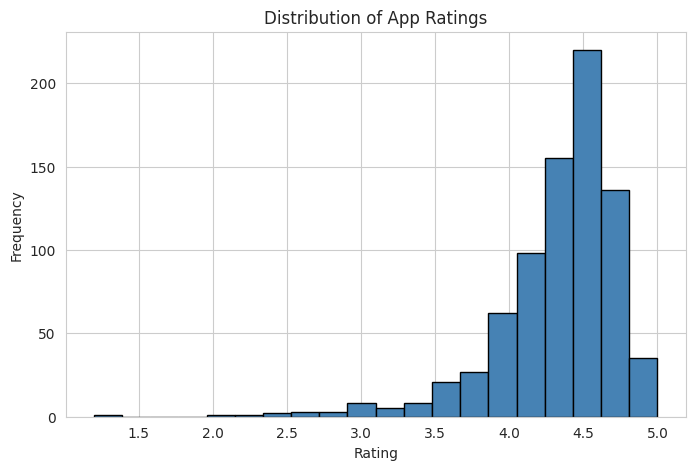

In [14]:
plt.hist(df['rating'], bins=20, color='steelblue', edgecolor='black')
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.show()

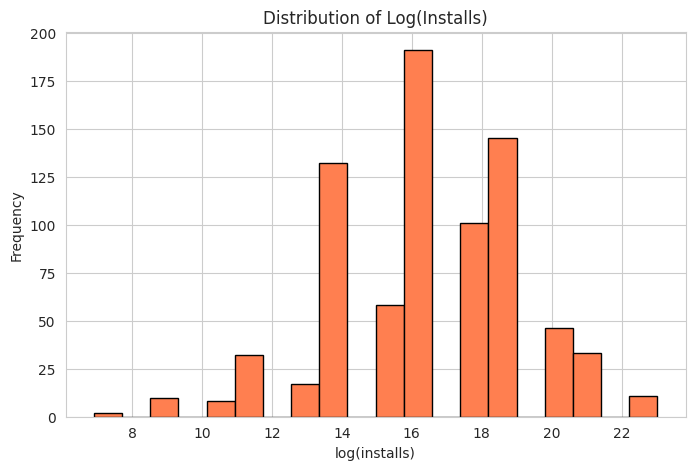

In [15]:
plt.hist(df['log_installs'], bins=20, color='coral', edgecolor='black')
plt.title('Distribution of Log(Installs)')
plt.xlabel('log(installs)')
plt.ylabel('Frequency')
plt.show()

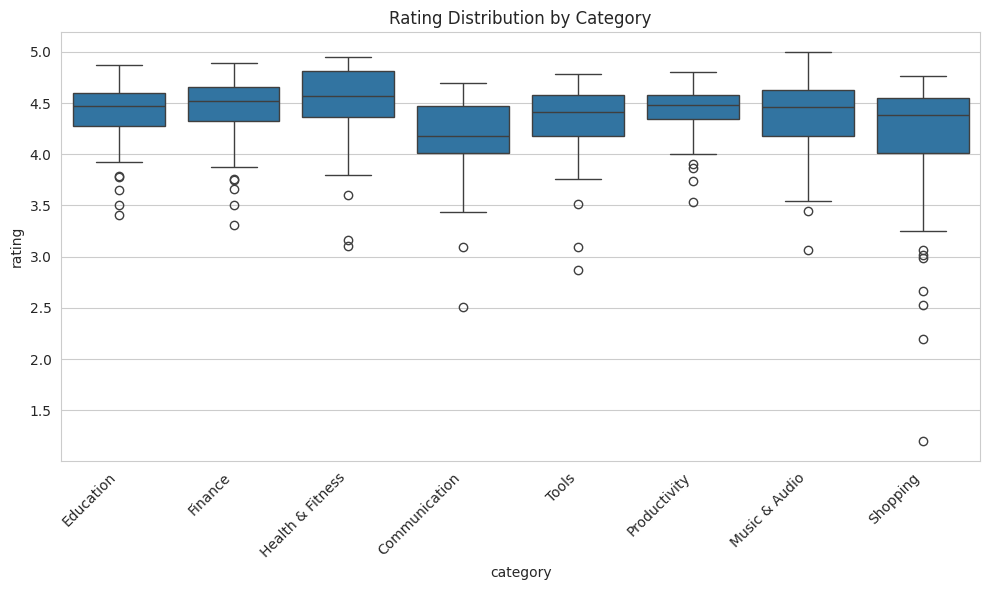

In [16]:
top_categories = df['category'].value_counts().head(8).index
subset = df[df['category'].isin(top_categories)]

plt.figure(figsize=(10, 6))
sns.boxplot(data=subset, x='category', y='rating')
plt.title('Rating Distribution by Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

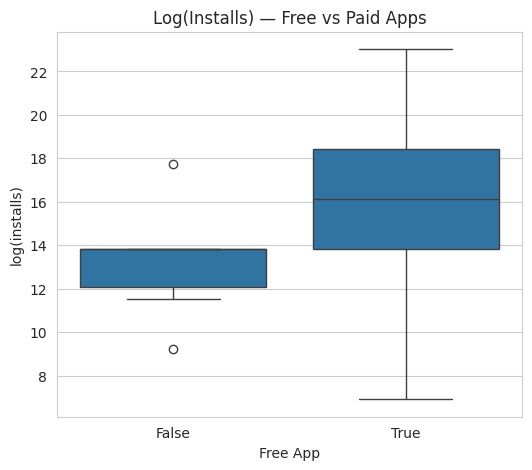

In [17]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x='free', y='log_installs')
plt.title('Log(Installs) — Free vs Paid Apps')
plt.xlabel('Free App')
plt.ylabel('log(installs)')
plt.show()

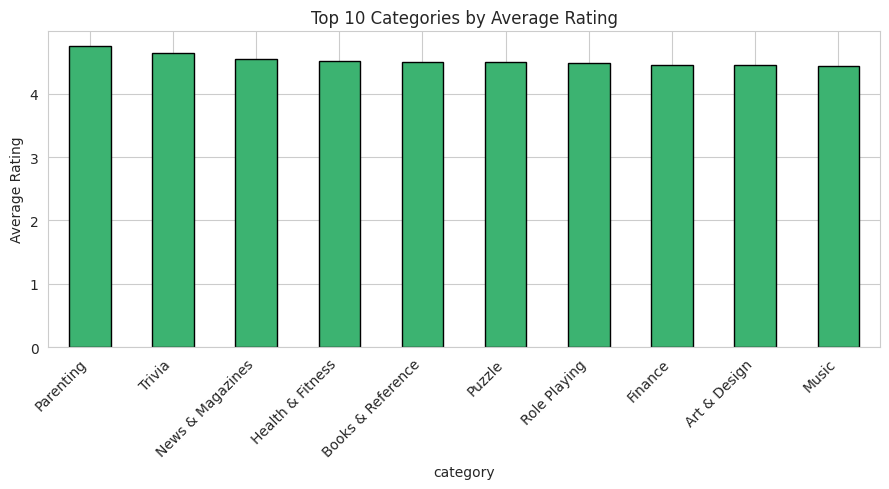

In [18]:
avg_rating = df.groupby('category')['rating'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
avg_rating.plot(kind='bar', color='mediumseagreen', edgecolor='black')
plt.title('Top 10 Categories by Average Rating')
plt.ylabel('Average Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

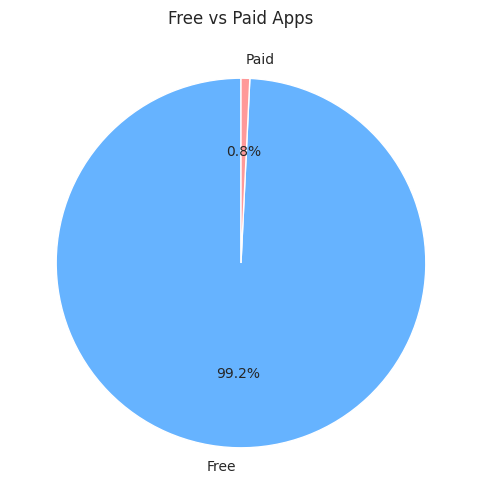

In [19]:
free_counts = df['free'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(free_counts, labels=['Free', 'Paid'], autopct='%1.1f%%',
        colors=['#66b3ff', '#ff9999'], startangle=90)
plt.title('Free vs Paid Apps')
plt.show()

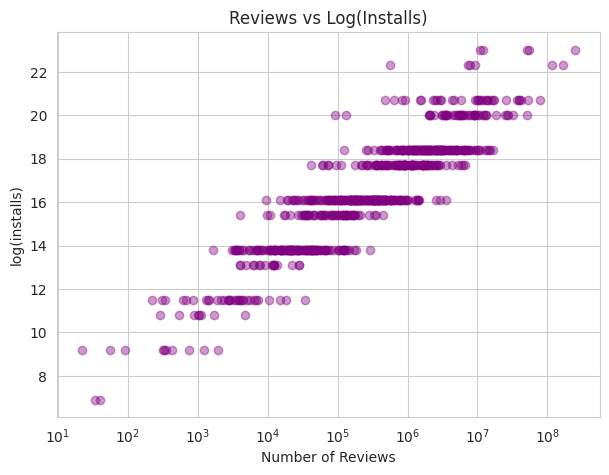

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(df['reviews'], df['log_installs'], alpha=0.4, color='purple')
plt.title('Reviews vs Log(Installs)')
plt.xlabel('Number of Reviews')
plt.ylabel('log(installs)')
plt.xscale('log')  # reviews also spans several orders of magnitude
plt.show()

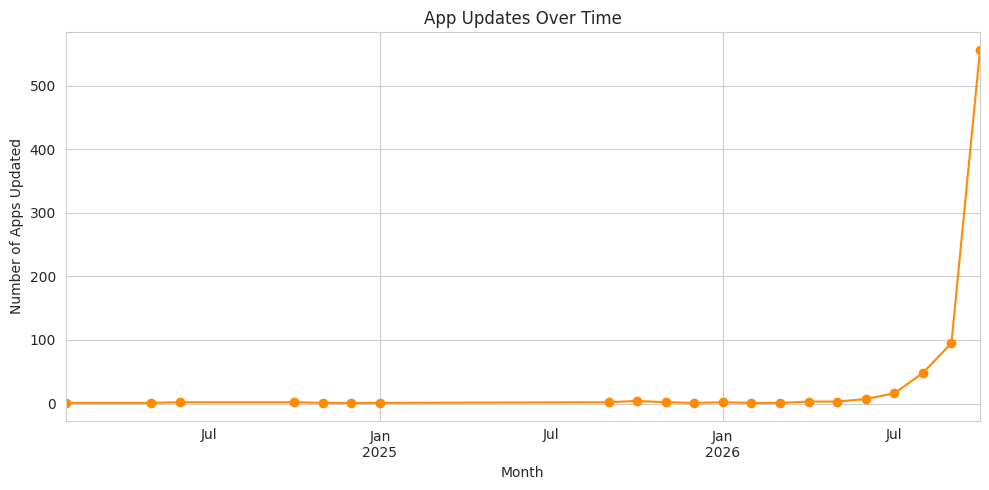

In [21]:
monthly_counts = df.dropna(subset=['last_updated_date']).groupby(
    df['last_updated_date'].dt.to_period('M')
).size()

plt.figure(figsize=(10, 5))
monthly_counts.plot(kind='line', marker='o', color='darkorange')
plt.title('App Updates Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Apps Updated')
plt.tight_layout()
plt.show()

Practical 3

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)  # for reproducible sampling

In [23]:
population_mean_rating = df['rating'].mean()
population_std_rating = df['rating'].std()

print(f"Population mean rating: {population_mean_rating:.3f}")
print(f"Population std rating: {population_std_rating:.3f}")
print(f"Population size: {len(df)}")

Population mean rating: 4.329
Population std rating: 0.423
Population size: 786


In [24]:
srs_sample = df.sample(n=100, random_state=42)

print("Simple Random Sample:")
print(f"Sample mean rating: {srs_sample['rating'].mean():.3f}")
print(f"Sample std rating: {srs_sample['rating'].std():.3f}")
print(f"Difference from population mean: {abs(srs_sample['rating'].mean() - population_mean_rating):.3f}")

Simple Random Sample:
Sample mean rating: 4.348
Sample std rating: 0.344
Difference from population mean: 0.019


In [25]:
def systematic_sample(data, k):
    start = np.random.randint(0, k)
    return data.iloc[start::k]

k = len(df) // 100  # gives ~100 samples
sys_sample = systematic_sample(df, k)

print(f"Systematic Sample (every {k}th row):")
print(f"Sample size: {len(sys_sample)}")
print(f"Sample mean rating: {sys_sample['rating'].mean():.3f}")
print(f"Difference from population mean: {abs(sys_sample['rating'].mean() - population_mean_rating):.3f}")

Systematic Sample (every 7th row):
Sample size: 112
Sample mean rating: 4.303
Difference from population mean: 0.026


In [26]:
# Sample proportionally from each category, preserving the population's category mix
strat_sample = df.groupby('category', group_keys=False).apply(
    lambda x: x.sample(frac=0.15, random_state=42)
)

print(f"Stratified Sample size: {len(strat_sample)}")
print(f"Sample mean rating: {strat_sample['rating'].mean():.3f}")
print(f"Difference from population mean: {abs(strat_sample['rating'].mean() - population_mean_rating):.3f}")

print("\nCategory proportions — population vs sample:")
comparison = pd.DataFrame({
    'population_%': df['category'].value_counts(normalize=True) * 100,
    'sample_%': strat_sample['category'].value_counts(normalize=True) * 100
}).head(8)
print(comparison)

Stratified Sample size: 116
Sample mean rating: 4.322
Difference from population mean: 0.007

Category proportions — population vs sample:
                   population_%  sample_%
category                                 
Action                 3.180662  3.448276
Adventure              0.254453       NaN
Arcade                 1.653944  1.724138
Art & Design           0.254453       NaN
Board                  0.636132  0.862069
Books & Reference      1.017812  0.862069
Business               0.636132  0.862069
Card                   3.307888  3.448276


/tmp/ipykernel_2212/4120594515.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  strat_sample = df.groupby('category', group_keys=False).apply(


In [27]:
results = pd.DataFrame({
    'Method': ['Population', 'Simple Random', 'Systematic', 'Stratified'],
    'Sample Size': [len(df), len(srs_sample), len(sys_sample), len(strat_sample)],
    'Mean Rating': [population_mean_rating, srs_sample['rating'].mean(),
                     sys_sample['rating'].mean(), strat_sample['rating'].mean()],
})
results['Abs Diff from Population'] = abs(results['Mean Rating'] - population_mean_rating)
print(results)

          Method  Sample Size  Mean Rating  Abs Diff from Population
0     Population          786     4.328978                  0.000000
1  Simple Random          100     4.347839                  0.018860
2     Systematic          112     4.303330                  0.025649
3     Stratified          116     4.322176                  0.006802


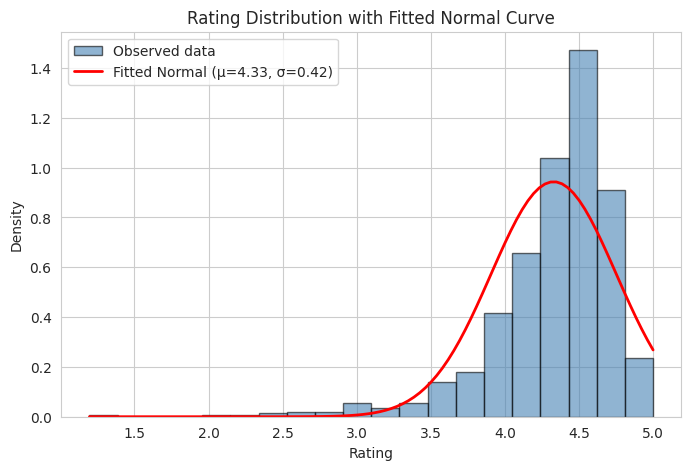

In [28]:
mu, sigma = stats.norm.fit(df['rating'])

plt.figure(figsize=(8, 5))
plt.hist(df['rating'], bins=20, density=True, alpha=0.6, color='steelblue', edgecolor='black', label='Observed data')

x = np.linspace(df['rating'].min(), df['rating'].max(), 100)
plt.plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label=f'Fitted Normal (μ={mu:.2f}, σ={sigma:.2f})')

plt.title('Rating Distribution with Fitted Normal Curve')
plt.xlabel('Rating')
plt.ylabel('Density')
plt.legend()
plt.show()

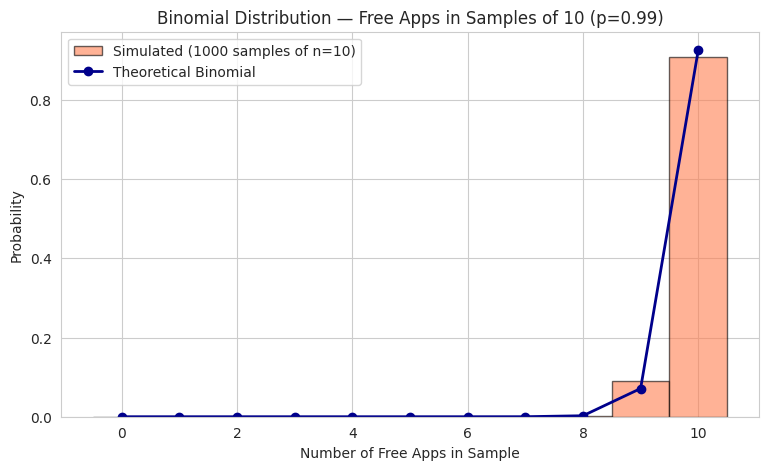

In [29]:
p_free = df['free'].mean()  # proportion of free apps = probability of "success"
n_trials = 10

# Theoretical binomial probabilities
k_values = np.arange(0, n_trials + 1)
theoretical_probs = stats.binom.pmf(k_values, n_trials, p_free)

# Empirical simulation: repeatedly draw samples of 10 apps, count how many are free
n_simulations = 1000
simulated_counts = [
    df.sample(n_trials, replace=True)['free'].sum()
    for _ in range(n_simulations)
]

plt.figure(figsize=(9, 5))
plt.hist(simulated_counts, bins=np.arange(-0.5, n_trials + 1.5, 1), density=True,
         alpha=0.6, color='coral', edgecolor='black', label='Simulated (1000 samples of n=10)')
plt.plot(k_values, theoretical_probs, 'o-', color='darkblue', linewidth=2, label='Theoretical Binomial')

plt.title(f'Binomial Distribution — Free Apps in Samples of {n_trials} (p={p_free:.2f})')
plt.xlabel('Number of Free Apps in Sample')
plt.ylabel('Probability')
plt.legend()
plt.show()

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

Population size: 786
Population mean (μ): 2,882,699.60
Population std (σ): 12,918,533.60
Population skewness: 12.80  (far from 0 = strongly non-normal)


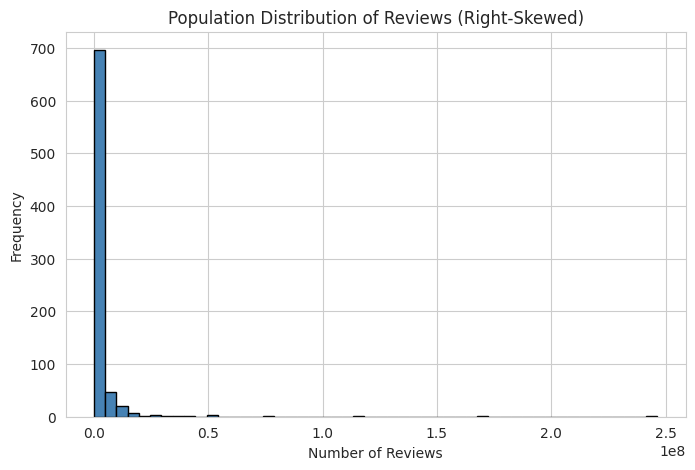

In [32]:
# 'reviews' is heavily right-skewed, which makes it a good test for CLT
population = df['reviews'].values
mu = population.mean()
sigma = population.std(ddof=0)

print(f"Population size: {len(population)}")
print(f"Population mean (μ): {mu:,.2f}")
print(f"Population std (σ): {sigma:,.2f}")
print(f"Population skewness: {stats.skew(population):.2f}  (far from 0 = strongly non-normal)")

plt.figure(figsize=(8, 5))
plt.hist(population, bins=50, color='steelblue', edgecolor='black')
plt.title('Population Distribution of Reviews (Right-Skewed)')
plt.xlabel('Number of Reviews')
plt.ylabel('Frequency')
plt.show()

In [33]:
sample_sizes = [5, 30, 100, 300]
n_reps = 1000

sampling_means = {
    n: [np.random.choice(population, size=n, replace=True).mean() for _ in range(n_reps)]
    for n in sample_sizes
}
print("Done: drew", n_reps, "samples for each of n =", sample_sizes)

Done: drew 1000 samples for each of n = [5, 30, 100, 300]


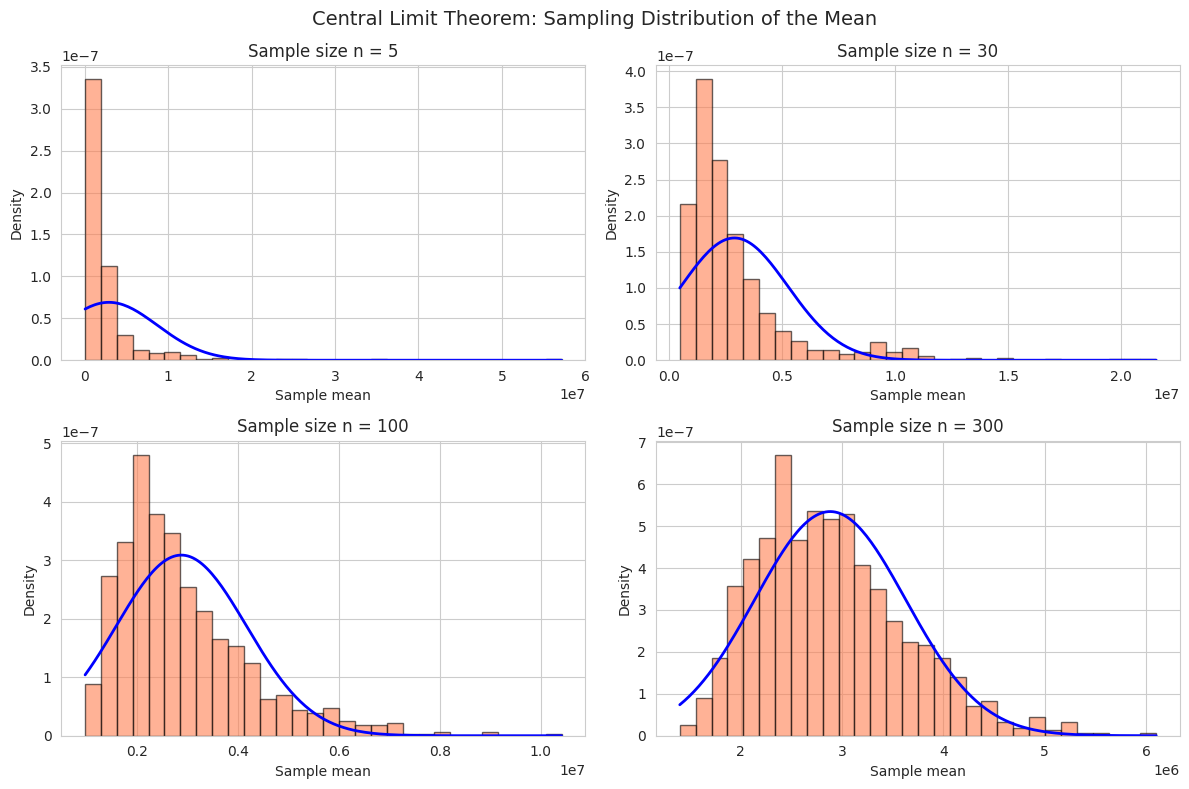

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, n in zip(axes.flatten(), sample_sizes):
    means = np.array(sampling_means[n])
    ax.hist(means, bins=30, density=True, alpha=0.6, color='coral', edgecolor='black')

    # Theoretical normal curve predicted by CLT: N(μ, σ/√n)
    x = np.linspace(means.min(), means.max(), 200)
    ax.plot(x, stats.norm.pdf(x, mu, sigma / np.sqrt(n)), 'b-', linewidth=2)

    ax.set_title(f'Sample size n = {n}')
    ax.set_xlabel('Sample mean')
    ax.set_ylabel('Density')

plt.suptitle('Central Limit Theorem: Sampling Distribution of the Mean', fontsize=14)
plt.tight_layout()
plt.show()

In [35]:
rows = []
for n in sample_sizes:
    means = np.array(sampling_means[n])
    rows.append({
        'n': n,
        'Mean of sample means': means.mean(),
        'Population mean (μ)': mu,
        'Empirical SE': means.std(ddof=1),
        'Theoretical SE (σ/√n)': sigma / np.sqrt(n),
        'Skewness of means': stats.skew(means)
    })

clt_table = pd.DataFrame(rows).round(3)
print(clt_table)

     n  Mean of sample means  Population mean (μ)  Empirical SE  \
0    5           2613216.246          2882699.595   4915344.425   
1   30           2881204.319          2882699.595   2492847.741   
2  100           2913864.904          2882699.595   1324256.073   
3  300           2889166.385          2882699.595    737441.276   

   Theoretical SE (σ/√n)  Skewness of means  
0            5777343.860              6.291  
1            2358590.754              2.818  
2            1291853.360              1.433  
3             745851.885              0.738  


In [37]:
sample = df.sample(n=100, random_state=1)

estimates = pd.DataFrame({
    'Parameter': ['Mean rating', 'Std of rating', 'Median rating', 'Proportion of free apps'],
    'Point estimate (sample)': [
        sample['rating'].mean(),
        sample['rating'].std(ddof=1),
        sample['rating'].median(),
        sample['free'].mean()
    ],
    'True value (population)': [
        df['rating'].mean(),
        df['rating'].std(ddof=1),
        df['rating'].median(),
        df['free'].mean()
    ]
})
estimates['Error'] = estimates['Point estimate (sample)'] - estimates['True value (population)']
print(estimates.round(4))

                 Parameter  Point estimate (sample)  True value (population)  \
0              Mean rating                   4.3520                   4.3290   
1            Std of rating                   0.3435                   0.4233   
2            Median rating                   4.4301                   4.4281   
3  Proportion of free apps                   1.0000                   0.9924   

    Error  
0  0.0231  
1 -0.0798  
2  0.0020  
3  0.0076  


In [38]:
pop_var = df['rating'].var(ddof=0)

var_biased = []    # divides by n
var_unbiased = []  # divides by n-1

for _ in range(2000):
    s = df['rating'].sample(n=30, replace=True)
    var_biased.append(s.var(ddof=0))
    var_unbiased.append(s.var(ddof=1))

print(f"Population variance:                {pop_var:.5f}")
print(f"Average of biased estimates (÷n):   {np.mean(var_biased):.5f}")
print(f"Average of unbiased estimates (÷n-1): {np.mean(var_unbiased):.5f}")

Population variance:                0.17893
Average of biased estimates (÷n):   0.17345
Average of unbiased estimates (÷n-1): 0.17943


In [39]:
sample = df['rating'].sample(n=100, random_state=1)
xbar = sample.mean()
se = sample.std(ddof=1) / np.sqrt(len(sample))
ci_low, ci_high = stats.t.interval(0.95, df=len(sample) - 1, loc=xbar, scale=se)

print(f"Sample mean: {xbar:.3f}")
print(f"95% CI for population mean rating: ({ci_low:.3f}, {ci_high:.3f})")
print(f"True population mean: {df['rating'].mean():.3f}")

# Coverage check: what % of 1000 intervals actually contain the true mean?
true_mean = df['rating'].mean()
hits = 0
for _ in range(1000):
    s = df['rating'].sample(n=100, replace=True)
    lo, hi = stats.t.interval(0.95, df=99, loc=s.mean(), scale=s.std(ddof=1) / np.sqrt(100))
    hits += (lo <= true_mean <= hi)
print(f"Coverage of 95% CIs over 1000 repeats: {hits / 10:.1f}%")

Sample mean: 4.352
95% CI for population mean rating: (4.284, 4.420)
True population mean: 4.329
Coverage of 95% CIs over 1000 repeats: 94.1%


In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm

alpha = 0.05

# Pick the two largest categories (we need n >= 30 per group for z-tests)
top_cats = df['category'].value_counts()
print(top_cats.head(6))
cat_a, cat_b = top_cats.index[0], top_cats.index[1]
print("\nCategories used:", cat_a, "and", cat_b)

category
Finance             106
Health & Fitness     88
Shopping             77
Education            69
Music & Audio        67
Productivity         50
Name: count, dtype: int64

Categories used: Finance and Health & Fitness


In [41]:
pop_mean = df['rating'].mean()
pop_sigma = df['rating'].std(ddof=0)   # treated as the known population σ

group = df[df['category'] == cat_a]['rating']
n = len(group)
xbar = group.mean()

z = (xbar - pop_mean) / (pop_sigma / np.sqrt(n))
p_value = 2 * (1 - norm.cdf(abs(z)))   # two-tailed

print(f"Category: {cat_a}  (n = {n})")
print(f"Sample mean = {xbar:.4f}, Population mean = {pop_mean:.4f}")
print(f"z-statistic = {z:.4f}")
print(f"p-value     = {p_value:.4f}")
print("Decision:", "Reject H0" if p_value < alpha else "Fail to reject H0")

Category: Finance  (n = 106)
Sample mean = 4.4567, Population mean = 4.3290
z-statistic = 3.1083
p-value     = 0.0019
Decision: Reject H0


In [42]:
from statsmodels.stats.weightstats import ztest

g1 = df[df['category'] == cat_a]['rating']
g2 = df[df['category'] == cat_b]['rating']

z_stat, p_val = ztest(g1, g2)

print(f"{cat_a}: n={len(g1)}, mean={g1.mean():.3f}")
print(f"{cat_b}: n={len(g2)}, mean={g2.mean():.3f}")
print(f"z-statistic = {z_stat:.4f}, p-value = {p_val:.4f}")
print("Decision:", "Reject H0" if p_val < alpha else "Fail to reject H0")

Finance: n=106, mean=4.457
Health & Fitness: n=88, mean=4.519
z-statistic = -1.3263, p-value = 0.1847
Decision: Fail to reject H0


In [43]:
sample = df['rating'].sample(n=25, random_state=42)   # small sample, so t-test is appropriate

t_stat, p_val = stats.ttest_1samp(sample, popmean=4.0)

print(f"Sample mean = {sample.mean():.4f}")
print(f"t-statistic = {t_stat:.4f}, p-value = {p_val:.4f}")
print("Decision:", "Reject H0" if p_val < alpha else "Fail to reject H0")

Sample mean = 4.3892
t-statistic = 6.2754, p-value = 0.0000
Decision: Reject H0


In [44]:
free_apps = df[df['free'] == True]['log_installs']
paid_apps = df[df['free'] == False]['log_installs']

print(f"Free apps: {len(free_apps)}, Paid apps: {len(paid_apps)}")

if len(paid_apps) >= 2:
    # Welch's t-test (does not assume equal variances)
    t_stat, p_val = stats.ttest_ind(free_apps, paid_apps, equal_var=False)
    print(f"Mean log(installs): Free = {free_apps.mean():.3f}, Paid = {paid_apps.mean():.3f}")
    print(f"t-statistic = {t_stat:.4f}, p-value = {p_val:.4f}")
    print("Decision:", "Reject H0" if p_val < alpha else "Fail to reject H0")
else:
    print("Too few paid apps for a t-test. Compare two categories instead.")

Free apps: 780, Paid apps: 6
Mean log(installs): Free = 16.432, Paid = 13.316
t-statistic = 2.6790, p-value = 0.0433
Decision: Reject H0


In [45]:
top5 = top_cats.head(5).index
subset = df[df['category'].isin(top5)]

groups = [subset[subset['category'] == c]['log_installs'] for c in top5]

f_stat, p_val = stats.f_oneway(*groups)

print("Group means:")
print(subset.groupby('category')['log_installs'].mean().round(3))
print(f"\nF-statistic = {f_stat:.4f}")
print(f"p-value     = {p_val:.4f}")
print("Decision:", "Reject H0 (at least one category differs)" if p_val < alpha else "Fail to reject H0")

Group means:
category
Education           15.123
Finance             15.724
Health & Fitness    15.406
Music & Audio       15.688
Shopping            16.210
Name: log_installs, dtype: float64

F-statistic = 2.1246
p-value     = 0.0770
Decision: Fail to reject H0


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Make sure the log columns exist
df['log_reviews'] = np.log1p(df['reviews'])
df['is_free'] = df['free'].astype(int)

num_cols = ['rating', 'log_reviews', 'log_installs', 'price']

cov_matrix = df[num_cols].cov()
print("=== Covariance matrix ===")
print(cov_matrix.round(4))

=== Covariance matrix ===
              rating  log_reviews  log_installs      price
rating        0.1792       0.0878       -0.0493     1.1253
log_reviews   0.0878       6.5887        6.0553    -9.5834
log_installs -0.0493       6.0553        6.7118   -15.3977
price         1.1253      -9.5834      -15.3977  2480.7459


In [49]:
x = df['log_reviews']
y = df['log_installs']

cov_manual = np.sum((x - x.mean()) * (y - y.mean())) / (len(df) - 1)
print(f"Manual covariance (log_reviews, log_installs): {cov_manual:.4f}")
print(f"Pandas covariance:                             {x.cov(y):.4f}")
print("Positive covariance means the two variables tend to move in the same direction.")

Manual covariance (log_reviews, log_installs): 6.0553
Pandas covariance:                             6.0553
Positive covariance means the two variables tend to move in the same direction.


In [50]:
corr_pearson = df[num_cols].corr(method='pearson')
print("=== Pearson correlation ===")
print(corr_pearson.round(3))

=== Pearson correlation ===
              rating  log_reviews  log_installs  price
rating         1.000        0.081        -0.045  0.053
log_reviews    0.081        1.000         0.911 -0.075
log_installs  -0.045        0.911         1.000 -0.119
price          0.053       -0.075        -0.119  1.000


In [51]:
raw_cols = ['rating', 'reviews', 'min_installs', 'price']

corr_spearman = df[raw_cols].corr(method='spearman')
print("=== Spearman rank correlation (raw, untransformed columns) ===")
print(corr_spearman.round(3))

=== Spearman rank correlation (raw, untransformed columns) ===
              rating  reviews  min_installs  price
rating         1.000   -0.007        -0.146  0.083
reviews       -0.007    1.000         0.909 -0.055
min_installs  -0.146    0.909         1.000 -0.092
price          0.083   -0.055        -0.092  1.000


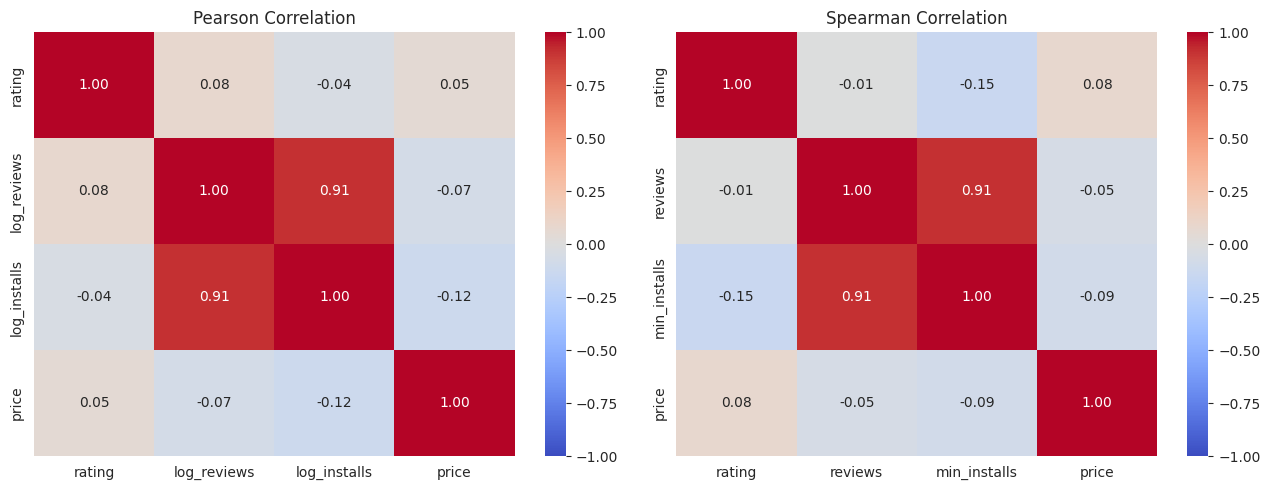

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            fmt='.2f', ax=axes[0])
axes[0].set_title('Pearson Correlation')

sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            fmt='.2f', ax=axes[1])
axes[1].set_title('Spearman Correlation')

plt.tight_layout()
plt.show()

In [53]:
alpha = 0.05

pairs = [('log_reviews', 'log_installs'),
         ('rating', 'log_installs'),
         ('rating', 'log_reviews')]

for a, b in pairs:
    r, p = stats.pearsonr(df[a], df[b])
    rho, p_s = stats.spearmanr(df[a], df[b])
    print(f"{a} vs {b}")
    print(f"  Pearson  r   = {r:.3f}, p = {p:.4g}")
    print(f"  Spearman rho = {rho:.3f}, p = {p_s:.4g}")
    print("  Decision:", "Significant correlation" if p < alpha else "No significant correlation")
    print()

log_reviews vs log_installs
  Pearson  r   = 0.911, p = 4.692e-303
  Spearman rho = 0.909, p = 1.09e-300
  Decision: Significant correlation

rating vs log_installs
  Pearson  r   = -0.045, p = 0.2076
  Spearman rho = -0.146, p = 3.952e-05
  Decision: No significant correlation

rating vs log_reviews
  Pearson  r   = 0.081, p = 0.0235
  Spearman rho = -0.007, p = 0.8447
  Decision: Significant correlation



In [55]:
cov_xy = df['log_reviews'].cov(df['log_installs'])
sx = df['log_reviews'].std()
sy = df['log_installs'].std()

print(f"Covariance        = {cov_xy:.4f}")
print(f"Std dev (x), (y)  = {sx:.4f}, {sy:.4f}")
print(f"cov / (sx * sy)   = {cov_xy / (sx * sy):.4f}")
print(f"Pearson r         = {df['log_reviews'].corr(df['log_installs']):.4f}")

Covariance        = 6.0553
Std dev (x), (y)  = 2.5668, 2.5907
cov / (sx * sy)   = 0.9106
Pearson r         = 0.9106


In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Reviews span several orders of magnitude, so log-transform them like installs
df['log_reviews'] = np.log1p(df['reviews'])
df['is_free'] = df['free'].astype(int)

def evaluate(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name}: R² = {r2:.3f} | RMSE = {rmse:.3f} | MAE = {mae:.3f}")

print(df[['log_installs', 'log_reviews', 'rating', 'is_free']].corr().round(3))

              log_installs  log_reviews  rating  is_free
log_installs         1.000        0.911  -0.045    0.105
log_reviews          0.911        1.000   0.081    0.051
rating              -0.045        0.081   1.000   -0.062
is_free              0.105        0.051  -0.062    1.000


In [57]:
X_simple = sm.add_constant(df['log_reviews'])
y = df['log_installs']

slr = sm.OLS(y, X_simple).fit()
print(slr.summary())

                            OLS Regression Results                            
Dep. Variable:           log_installs   R-squared:                       0.829
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                     3805.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          4.69e-303
Time:                        01:42:41   Log-Likelihood:                -1168.6
No. Observations:                 786   AIC:                             2341.
Df Residuals:                     784   BIC:                             2350.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           4.9864      0.189     26.374      

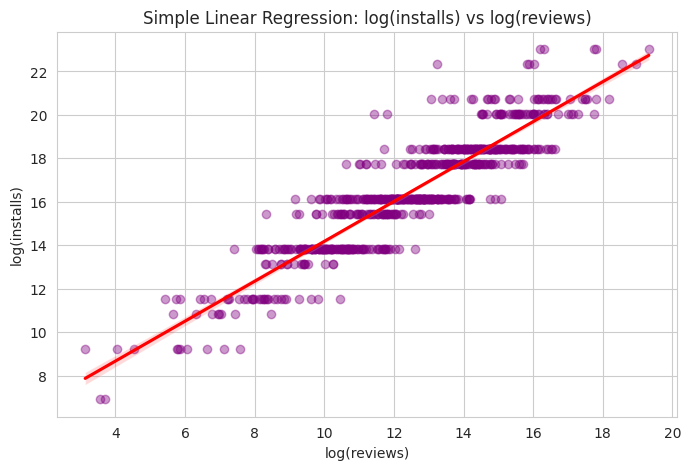

In [58]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='log_reviews', y='log_installs',
            scatter_kws={'alpha': 0.4, 'color': 'purple'}, line_kws={'color': 'red'})
plt.title('Simple Linear Regression: log(installs) vs log(reviews)')
plt.xlabel('log(reviews)')
plt.ylabel('log(installs)')
plt.show()

In [59]:
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    df[['log_reviews']], df['log_installs'], test_size=0.2, random_state=42
)

lr = LinearRegression().fit(Xs_train, ys_train)
print(f"Intercept: {lr.intercept_:.3f}, Slope: {lr.coef_[0]:.3f}")

evaluate("Simple regression (train)", ys_train, lr.predict(Xs_train))
evaluate("Simple regression (test) ", ys_test, lr.predict(Xs_test))

Intercept: 5.028, Slope: 0.912
Simple regression (train): R² = 0.835 | RMSE = 1.031 | MAE = 0.790
Simple regression (test) : R² = 0.803 | RMSE = 1.217 | MAE = 0.907


In [60]:
# Keep the 8 biggest categories and group the rest as 'Other' (avoids dozens of dummy columns)
top_cats = df['category'].value_counts().head(8).index
df['category_grp'] = df['category'].where(df['category'].isin(top_cats), 'Other')

features = df[['log_reviews', 'rating', 'is_free', 'category_grp', 'content_rating']]
X = pd.get_dummies(features, columns=['category_grp', 'content_rating'],
                   drop_first=True, dtype=float)
y = df['log_installs']

print(X.columns.tolist())
print("Shape:", X.shape)

['log_reviews', 'rating', 'is_free', 'category_grp_Education', 'category_grp_Finance', 'category_grp_Health & Fitness', 'category_grp_Music & Audio', 'category_grp_Other', 'category_grp_Productivity', 'category_grp_Shopping', 'category_grp_Tools', 'content_rating_Rated for 16+', 'content_rating_Rated for 18+', 'content_rating_Rated for 3+', 'content_rating_Rated for 7+']
Shape: (786, 15)


In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlr_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(mlr_sm.summary())

                            OLS Regression Results                            
Dep. Variable:           log_installs   R-squared:                       0.861
Model:                            OLS   Adj. R-squared:                  0.858
Method:                 Least Squares   F-statistic:                     253.0
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          1.40e-250
Time:                        01:42:56   Log-Likelihood:                -857.00
No. Observations:                 628   AIC:                             1746.
Df Residuals:                     612   BIC:                             1817.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

In [62]:
mlr = LinearRegression().fit(X_train, y_train)
simple = LinearRegression().fit(X_train[['log_reviews']], y_train)

evaluate("Simple   (test)", y_test, simple.predict(X_test[['log_reviews']]))
evaluate("Multiple (test)", y_test, mlr.predict(X_test))
evaluate("Multiple (train)", y_train, mlr.predict(X_train))

Simple   (test): R² = 0.803 | RMSE = 1.217 | MAE = 0.907
Multiple (test): R² = 0.830 | RMSE = 1.130 | MAE = 0.833
Multiple (train): R² = 0.861 | RMSE = 0.947 | MAE = 0.730


In [64]:
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': mlr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print(f"Intercept: {mlr.intercept_:.3f}")
print(coef_table.round(3))

Intercept: 6.548
                          Feature  Coefficient
2                         is_free        1.449
0                     log_reviews        0.916
14    content_rating_Rated for 7+        0.673
1                          rating       -0.650
4            category_grp_Finance       -0.529
8       category_grp_Productivity        0.429
11   content_rating_Rated for 16+       -0.424
5   category_grp_Health & Fitness       -0.418
3          category_grp_Education       -0.402
9           category_grp_Shopping       -0.389
12   content_rating_Rated for 18+       -0.376
6      category_grp_Music & Audio       -0.168
7              category_grp_Other       -0.106
10             category_grp_Tools        0.103
13    content_rating_Rated for 3+        0.091


In [65]:
# First check valid category and content-rating values
print("Categories:", sorted(df['category_grp'].unique()))
print("Content ratings:", df['content_rating'].unique())

# Describe the new app (edit these values)
new_app = pd.DataFrame([{
    'log_reviews': np.log1p(15000),   # 15,000 reviews
    'rating': 4.3,
    'is_free': 1,
    'category_grp': 'Tools',          # must match one of the categories printed above
    'content_rating': 'Everyone'
}])

# Encode the same way as training data, then align columns
new_X = pd.get_dummies(new_app, columns=['category_grp', 'content_rating'], dtype=float)
new_X = new_X.reindex(columns=X.columns, fill_value=0)

pred_log = mlr.predict(new_X)[0]
print(f"\nPredicted log(installs): {pred_log:.3f}")
print(f"Predicted installs: {np.expm1(pred_log):,.0f}")

Categories: ['Communication', 'Education', 'Finance', 'Health & Fitness', 'Music & Audio', 'Other', 'Productivity', 'Shopping', 'Tools']
Content ratings: ['Rated for 16+' 'Rated for 12+' 'Rated for 18+' 'Rated for 3+'
 'Rated for 7+']

Predicted log(installs): 14.108
Predicted installs: 1,339,291


In [66]:
!pip install streamlit plotly -q

In [68]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false &>/content/logs.txt &
!./cloudflared tunnel --url http://localhost:8501

2026-10-27T01:50:46Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-27T01:50:46Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-27T01:50:50Z INF +--------------------------------------------------------------------------------------------+
2026-10-27T01:50:50Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-27T01:50:50Z INF |  https://month-drainage-assist-suffering.trycloudflare

In [ ]:
import numpy as np, pandas as pd, gradio as gr
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

data = df.copy().dropna(subset=['content_rating'])
data['log_reviews'] = np.log1p(data['reviews'])
data['is_free'] = data['free'].astype(int)
data['pricing'] = data['is_free'].map({1: 'Free', 0: 'Paid'})

top_cats = data['category'].value_counts().head(8).index.tolist()
data['category_grp'] = data['category'].where(data['category'].isin(top_cats), 'Other')

cat_options = sorted(data['category_grp'].unique())
cr_options = sorted(data['content_rating'].unique())

X = pd.get_dummies(
    data[['log_reviews', 'rating', 'is_free', 'category_grp', 'content_rating']],
    columns=['category_grp', 'content_rating'], drop_first=True, dtype=float)
y = data['log_installs']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)

test_pred = model.predict(X_test)
r2 = r2_score(y_test, test_pred)
mae = mean_absolute_error(y_test, test_pred)
rmse = np.sqrt(mean_squared_error(y_test, test_pred))
resid_std = np.std(y_train - model.predict(X_train))

INDIGO, VIOLET, ORANGE, GREEN = '#4f46e5', '#7c3aed', '#f97316', '#10b981'
print(f"Ready | apps: {len(data)} | test R² = {r2:.3f}")

Ready | apps: 783 | test R² = 0.857


In [ ]:
def predict_log(reviews, rating, is_free, category, content_rating):
    row = pd.DataFrame([{
        'log_reviews': np.log1p(max(reviews or 0, 0)), 'rating': rating,
        'is_free': is_free, 'category_grp': category, 'content_rating': content_rating}])
    row = pd.get_dummies(row, columns=['category_grp', 'content_rating'],
                         dtype=float).reindex(columns=X.columns, fill_value=0)
    return float(model.predict(row)[0])

def tier(n):
    if n < 10_000:      return "Niche", "#64748b", "🌱"
    if n < 1_000_000:   return "Growing", "#0ea5e9", "📈"
    if n < 100_000_000: return "Popular", "#f97316", "🔥"
    return "Blockbuster", "#7c3aed", "🚀"

def result_card(est, low, high, pct, p):
    name, color, icon = tier(est)
    return f"""
    <div style="background:white;border:1px solid #e2e8f0;border-radius:16px;padding:22px;color:#0f172a">
      <div style="font-size:13px;color:#64748b;letter-spacing:.06em">PREDICTED INSTALLS</div>
      <div style="font-size:42px;font-weight:800;color:{INDIGO};line-height:1.1">{est:,.0f}</div>
      <div style="margin:6px 0 14px;color:#475569">95% range: <b>{low:,.0f}</b> to <b>{high:,.0f}</b></div>
      <span style="background:{color};color:white;padding:5px 14px;border-radius:999px;font-weight:600">
        {icon} {name}</span>
      <div style="margin-top:18px;font-size:13px;color:#475569">
        Ahead of <b>{pct:.0f}%</b> of the {len(data)} apps in the dataset</div>
      <div style="background:#e2e8f0;border-radius:999px;height:10px;margin-top:6px">
        <div style="width:{pct:.0f}%;background:linear-gradient(90deg,{INDIGO},{VIOLET});
                    height:10px;border-radius:999px"></div></div>
    </div>"""

def predict(reviews, rating, pricing, category, content_rating):
    is_free = int(pricing == 'Free')
    p = predict_log(reviews, rating, is_free, category, content_rating)
    est = max(np.expm1(p), 0)
    low = max(np.expm1(p - 1.96 * resid_std), 0)
    high = np.expm1(p + 1.96 * resid_std)
    pct = (data['log_installs'] < p).mean() * 100

    # Where the app sits in the population
    fig1 = go.Figure(go.Histogram(x=data['log_installs'], nbinsx=25, marker_color='#c7d2fe'))
    fig1.add_vrect(x0=p - 1.96 * resid_std, x1=p + 1.96 * resid_std,
                   fillcolor=INDIGO, opacity=0.12, line_width=0)
    fig1.add_vline(x=p, line_color=INDIGO, line_width=3,
                   annotation_text="Your app", annotation_position="top")
    fig1.update_layout(title="Where your app sits among scraped apps", template="plotly_white",
                       xaxis_title="log(installs)", yaxis_title="Number of apps",
                       height=320, margin=dict(l=20, r=20, t=50, b=20), showlegend=False)

    # What-if analysis
    ratings = np.arange(1, 5.01, 0.25)
    rev_grid = np.logspace(1, 7, 25)
    est_vs_rating = [np.expm1(predict_log(reviews, r_, is_free, category, content_rating)) for r_ in ratings]
    est_vs_reviews = [np.expm1(predict_log(rv, rating, is_free, category, content_rating)) for rv in rev_grid]

    fig2 = make_subplots(rows=1, cols=2, subplot_titles=("If the rating changes", "If the reviews change"))
    fig2.add_trace(go.Scatter(x=ratings, y=est_vs_rating, mode='lines+markers',
                              line=dict(color=ORANGE, width=3)), row=1, col=1)
    fig2.add_trace(go.Scatter(x=rev_grid, y=est_vs_reviews, mode='lines',
                              line=dict(color=GREEN, width=3)), row=1, col=2)
    fig2.update_xaxes(title_text="Rating", row=1, col=1)
    fig2.update_xaxes(title_text="Reviews", type="log", row=1, col=2)
    fig2.update_yaxes(title_text="Predicted installs", type="log")
    fig2.update_layout(template="plotly_white", height=320, showlegend=False,
                       margin=dict(l=20, r=20, t=50, b=20))

    # Similar apps in the same category with the closest review count
    pool = data[data['category_grp'] == category].copy()
    pool['gap'] = (pool['log_reviews'] - np.log1p(max(reviews or 0, 0))).abs()
    similar = pool.sort_values('gap').head(6)[['name', 'rating', 'reviews', 'min_installs']]
    similar.columns = ['App', 'Rating', 'Reviews', 'Installs (lower bound)']

    return result_card(est, low, high, pct, p), fig1, fig2, similar

def explore(chart, category):
    d = data if category == 'All' else data[data['category_grp'] == category]
    if chart == 'Rating distribution':
        fig = px.histogram(d, x='rating', nbins=20, color_discrete_sequence=[INDIGO])
    elif chart == 'Installs distribution (log)':
        fig = px.histogram(d, x='log_installs', nbins=20, color_discrete_sequence=[ORANGE])
    elif chart == 'Reviews vs installs':
        fig = px.scatter(d, x='log_reviews', y='log_installs', color='category_grp',
                         hover_name='name', opacity=0.7)
    elif chart == 'Free vs paid':
        fig = px.pie(d, names='pricing', color_discrete_sequence=[INDIGO, ORANGE], hole=0.45)
    elif chart == 'Rating by category':
        fig = px.box(data, x='category_grp', y='rating', color='category_grp')
    else:
        counts = data['category_grp'].value_counts().reset_index()
        counts.columns = ['category', 'apps']
        fig = px.bar(counts, x='category', y='apps', color_discrete_sequence=[VIOLET])
    fig.update_layout(template="plotly_white", height=430, margin=dict(l=20, r=20, t=40, b=20),
                      title=f"{chart}  |  {category}  (n = {len(d)})")
    return fig

def model_report():
    coefs = pd.Series(model.coef_, index=X.columns)
    top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(10).index)[::-1]
    resid = y_test - test_pred

    fig = make_subplots(rows=1, cols=3, subplot_titles=(
        "Top 10 coefficients", "Actual vs predicted (test)", "Residual distribution"))
    fig.add_trace(go.Bar(x=top.values, y=top.index, orientation='h',
                         marker_color=[INDIGO if v > 0 else '#ef4444' for v in top.values]), row=1, col=1)
    fig.add_trace(go.Scatter(x=y_test, y=test_pred, mode='markers',
                             marker=dict(color=GREEN, opacity=0.6)), row=1, col=2)
    fig.add_trace(go.Scatter(x=[y.min(), y.max()], y=[y.min(), y.max()], mode='lines',
                             line=dict(color='red', dash='dash')), row=1, col=2)
    fig.add_trace(go.Histogram(x=resid, nbinsx=20, marker_color='#94a3b8'), row=1, col=3)
    fig.update_layout(template="plotly_white", height=420, showlegend=False,
                      margin=dict(l=20, r=20, t=50, b=20))
    return fig

def search_apps(q, category, min_rating, sort_by):
    t = data.copy()
    if q: t = t[t['name'].str.contains(q, case=False, na=False)]
    if category != 'All': t = t[t['category_grp'] == category]
    t = t[t['rating'] >= min_rating]
    t = t.sort_values(sort_by, ascending=False)
    out = t[['name', 'category', 'rating', 'reviews', 'min_installs']].head(100)
    out.columns = ['App', 'Category', 'Rating', 'Reviews', 'Installs (lower bound)']
    return out

def stat_card(label, value, color):
    return (f'<div style="flex:1;min-width:150px;background:white;border:1px solid #e2e8f0;'
            f'border-radius:14px;padding:14px 18px;color:#0f172a">'
            f'<div style="font-size:12px;color:#64748b;letter-spacing:.06em">{label}</div>'
            f'<div style="font-size:26px;font-weight:800;color:{color}">{value}</div></div>')

In [ ]:
css = """
.gradio-container {max-width: 1200px !important; margin: auto;}
button.primary {background: linear-gradient(135deg, #4f46e5, #7c3aed) !important; border: none !important;
                font-weight: 700 !important;}
"""

banner = f"""
<div style="background:linear-gradient(135deg,#4f46e5,#7c3aed);padding:30px;border-radius:18px;color:white">
  <h1 style="margin:0;font-size:30px">📱 Play Store App Popularity Predictor</h1>
  <p style="margin:8px 0 0;opacity:.92">Regression-based prediction of app installs from reviews, rating,
  pricing, category and content rating.</p>
</div>
<div style="display:flex;gap:12px;flex-wrap:wrap;margin-top:14px">
  {stat_card("APPS SCRAPED", f"{len(data):,}", INDIGO)}
  {stat_card("CATEGORIES", len(cat_options), VIOLET)}
  {stat_card("MODEL R² (TEST)", f"{r2:.2f}", GREEN)}
  {stat_card("MEDIAN INSTALLS", f"{data['min_installs'].median():,.0f}", ORANGE)}
</div>"""

with gr.Blocks(theme=gr.themes.Soft(primary_hue="indigo"), css=css, title="Play Store Predictor") as demo:
    gr.HTML(banner)

    with gr.Tabs():
        with gr.Tab("🔮 Predict"):
            with gr.Row():
                with gr.Column(scale=2):
                    gr.Markdown("### Describe your app")
                    reviews_in = gr.Number(value=15000, label="Number of reviews", minimum=0)
                    rating_in = gr.Slider(1, 5, value=4.3, step=0.1, label="Average rating")
                    pricing_in = gr.Radio(["Free", "Paid"], value="Free", label="Pricing")
                    cat_in = gr.Dropdown(cat_options, value=cat_options[0], label="Category")
                    cr_in = gr.Dropdown(cr_options, value=cr_options[0], label="Content rating")
                    btn = gr.Button("Predict installs", variant="primary", size="lg")
                with gr.Column(scale=3):
                    out_card = gr.HTML()
                    out_hist = gr.Plot()
            out_whatif = gr.Plot()
            gr.Markdown("### Similar apps in the same category")
            out_similar = gr.Dataframe(interactive=False)

            inputs = [reviews_in, rating_in, pricing_in, cat_in, cr_in]
            outputs = [out_card, out_hist, out_whatif, out_similar]
            btn.click(predict, inputs, outputs)
            demo.load(predict, inputs, outputs)

        with gr.Tab("📊 Data Explorer"):
            with gr.Row():
                chart_in = gr.Dropdown(
                    ['Rating distribution', 'Installs distribution (log)', 'Reviews vs installs',
                     'Free vs paid', 'Rating by category', 'Apps per category'],
                    value='Rating distribution', label="Chart")
                cat_f = gr.Dropdown(['All'] + cat_options, value='All', label="Filter by category")
            exp_plot = gr.Plot()
            chart_in.change(explore, [chart_in, cat_f], exp_plot)
            cat_f.change(explore, [chart_in, cat_f], exp_plot)
            demo.load(explore, [chart_in, cat_f], exp_plot)

        with gr.Tab("📈 Model Report"):
            gr.HTML(f"""<div style="display:flex;gap:12px;flex-wrap:wrap">
              {stat_card("R² (TEST)", f"{r2:.3f}", GREEN)}
              {stat_card("RMSE", f"{rmse:.3f}", ORANGE)}
              {stat_card("MAE", f"{mae:.3f}", VIOLET)}
              {stat_card("TRAIN / TEST", f"{len(X_train)} / {len(X_test)}", INDIGO)}
            </div>""")
            rep_plot = gr.Plot()
            demo.load(model_report, None, rep_plot)
            gr.Markdown("Errors are on the **log(installs)** scale. Predictions are approximate because "
                        "Google Play only reports install *ranges* (for example '10,000+').")

        with gr.Tab("🔎 Search Apps"):
            with gr.Row():
                q_in = gr.Textbox(label="App name contains", placeholder="e.g. whatsapp")
                s_cat = gr.Dropdown(['All'] + cat_options, value='All', label="Category")
                s_min = gr.Slider(1, 5, value=1, step=0.1, label="Minimum rating")
                s_sort = gr.Dropdown(['min_installs', 'reviews', 'rating'], value='min_installs', label="Sort by")
            table = gr.Dataframe(interactive=False)
            s_inputs = [q_in, s_cat, s_min, s_sort]
            for comp in s_inputs:
                comp.change(search_apps, s_inputs, table)
            demo.load(search_apps, s_inputs, table)

demo.launch(share=True)

/tmp/ipykernel_2772/263480225.py:20: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft(primary_hue="indigo"), css=css, title="Play Store Predictor") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://479fc266d9f2c44212.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
